In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
from scipy import stats


sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries loaded.")

Libraries loaded.


In [2]:
df=pd.read_csv(r"D:\ML\Project 1\bikes.csv")

In [3]:
df.head()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


In [4]:
df.tail()

,model_name,model_year,kms_driven,owner,location,mileage,power,price
7852,Yamaha YZF-R15 150cc 2011,2011,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,2015,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,2016,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000
7856,Bajaj Pulsar 220cc 2016,2016,15000 Km,first owner,chennai,\n\n 38 kmpl,21 bhp,65000


In [5]:
df['owner'].unique

<bound method Series.unique of 0       first owner
1       first owner
2       first owner
3       first owner
4       first owner
           ...     
7852    first owner
7853    first owner
7854    first owner
7855    first owner
7856    first owner
Name: owner, Length: 7857, dtype: str>

In [6]:
df.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [9]:
df.describe()

,model_year,price
count,7857.00,7857.00
mean,2015.37,106791.34
std,4.00,138926.12
min,1950.00,0.00
25%,2014.00,42000.00
50%,2016.00,75000.00
75%,2018.00,125000.00
max,2021.00,3000000.00


In [10]:
df.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [11]:
df[['kms_driven','mileage','power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [12]:
def get_number(value):
    if pd.isna(value):
        return np.nan
    value=str(value).replace (',','')
    number=''
    dot_used= False

    for i in value:
       if i.isdigit():
           number+=i
       elif i==',' and not dot_used:
           dot_used=True
       elif number:
          break
    return float(number) if number else np.nan

In [13]:
df['mileage'] .apply(get_number)

0      35.00
1      35.00
2      30.00
3      28.00
4        NaN
        ... 
7852   42.00
7853   80.00
7854   65.00
7855   57.00
7856   38.00
Name: mileage, Length: 7857, dtype: float64

In [14]:
column_name=['mileage','power','price','model_year','kms_driven']
for i in column_name:
    df[i]= df[i].apply(get_number)

In [15]:
df.info

<bound method DataFrame.info of                             model_name  model_year  kms_driven        owner  \
0        Bajaj Avenger Cruise 220 2017     2017.00    17000.00  first owner   
1     Royal Enfield Classic 350cc 2016     2016.00    50000.00  first owner   
2                  Hyosung GT250R 2012     2012.00    14795.00  first owner   
3           Bajaj Dominar 400 ABS 2017     2017.00       28.00  first owner   
4                Jawa Perak 330cc 2020     2020.00     2000.00  first owner   
...                                ...         ...         ...          ...   
7852         Yamaha YZF-R15 150cc 2011     2011.00     7000.00  first owner   
7853         Bajaj Discover 100cc 2015     2015.00       80.00  first owner   
7854           Bajaj Pulsar 180cc 2016     2016.00     6407.00  first owner   
7855              Bajaj V15 150cc 2016     2016.00     7524.00  first owner   
7856           Bajaj Pulsar 220cc 2016     2016.00    15000.00  first owner   

         location  

In [16]:
df.dropna(subset='price')

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,19.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,34.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,7.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,11.00,49000.00


In [17]:
df=df[df['price']>0]


In [18]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,19.00,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,34.00,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,7.00,28000.00
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,11.00,49000.00


In [19]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982.00,22000.00,first owner,pune,NaN,NaN,150000.00
1716,Royal Enfield Bullet 350 cc 1982,1982.00,16245.00,first owner,delhi,NaN,NaN,70000.00
2211,Bajaj Pulsar NS 200cc 2013,1950.00,35.00,first owner,noida,35.00,23.00,55000.00
2487,Royal Enfield Bullet 350 cc 1982,1982.00,3000.00,second owner,lalitpur,NaN,NaN,130000.00
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978.00,85000.00,first owner,chikamaglur,NaN,NaN,100000.00
2714,Royal Enfield Bullet 350 cc 1982,1982.00,21000.00,first owner,nashik,NaN,NaN,170000.00
3088,Royal Enfield Bullet 350 cc 1982,1982.00,10000.00,first owner,mumbai,NaN,NaN,60000.00
3429,Royal Enfield‎ Bullet 350cc 1970,1970.00,5000.00,third owner,pune,25.00,19.00,190000.00
4174,Royal Enfield Standard 350cc 1985,1985.00,40.00,third owner,kolhapur,40.00,18.00,125000.00
4258,Bajaj Pulsar NS 200cc 2013,1950.00,35.00,third owner,khalilabad,35.00,23.00,55000.00


In [20]:
pd. Timestamp.today().year

2026

In [21]:
if 'model_year' in df.columns:
    current_year = pd. Timestamp.today().year
    df['model_year']= df['model_year'].between(1998,current_year)

SECOND PART 
     |
     v

In [22]:
if 'model_year'in df.columns:
    current_year = pd.Timestamp.today().year
    df['bike_age'] = current_year - df['model_year']


if "location" in df.columns:
    df['location']= df['location'].fillna("Unknown")


print("missing values after basic cleaing:")
print(df.isnull().sum())

missing values after basic cleaing:
model_name      0
model_year      0
kms_driven      3
owner           0
location        0
mileage       772
power          31
price           0
bike_age        0
dtype: int64


In [58]:
df_clean = df.copy()
df_clean.to_csv("bikes_cleaned",index=False)

print("cleand dataset saved as bike_cleaned.csv")
display(df_clean.head())

cleand dataset saved as bike_cleaned.csv


,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,2025
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,19.00,115000.00,2025
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,2025
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,34.00,100000.00,2025
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00,2025


In [59]:
df_clean.describe()

,kms_driven,mileage,power,price,bike_age
count,7823.00,7054.00,7795.00,7826.00,7826.00
mean,17225.95,44.75,20.44,107214.35,2025.00
std,26764.52,16.96,15.05,139038.02,0.06
min,0.00,5.00,6.00,2000.00,2025.00
25%,104.00,35.00,14.00,42500.00,2025.00
50%,11000.00,40.00,19.00,75000.00,2025.00
75%,24858.00,57.00,24.00,125000.00,2025.00
max,1000000.00,104.00,197.00,3000000.00,2026.00


In [60]:
df_clean.skew

<bound method DataFrame.skew of                             model_name  model_year  kms_driven        owner  \
0        Bajaj Avenger Cruise 220 2017        True    17000.00  first owner   
1     Royal Enfield Classic 350cc 2016        True    50000.00  first owner   
2                  Hyosung GT250R 2012        True    14795.00  first owner   
3           Bajaj Dominar 400 ABS 2017        True       28.00  first owner   
4                Jawa Perak 330cc 2020        True     2000.00  first owner   
...                                ...         ...         ...          ...   
7852         Yamaha YZF-R15 150cc 2011        True     7000.00  first owner   
7853         Bajaj Discover 100cc 2015        True       80.00  first owner   
7854           Bajaj Pulsar 180cc 2016        True     6407.00  first owner   
7855              Bajaj V15 150cc 2016        True     7524.00  first owner   
7856           Bajaj Pulsar 220cc 2016        True    15000.00  first owner   

         location  

<Axes: xlabel='price', ylabel='Count'>

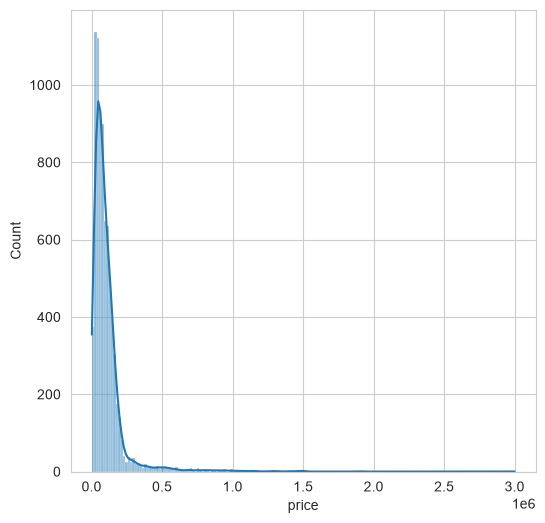

In [61]:
plt.figure(figsize=(6,6))
sns.histplot(df_clean['price'],kde=True)

<Axes: xlabel='price'>

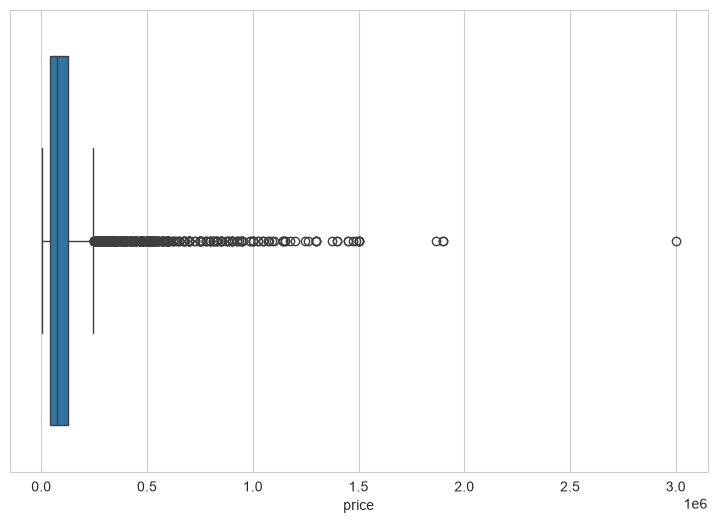

In [62]:
plt.figure(figsize=(9,6))
sns.boxplot(x=df_clean['price'])

In [63]:
df_clean['brand']=df_clean['model_name'].str.split().str[0]

In [64]:
df_clean['brand']=df_clean['brand'].str.lower()

In [66]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,19.00,115000.00,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,34.00,100000.00,2025,bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00,2025,jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,2025,yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,7.00,28000.00,2025,bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,2025,bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,11.00,49000.00,2025,bajaj


In [67]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()


In [68]:
brand_stats

,brand,median,mean,count
0,aprilia,1000000.00,1000000.00,2
1,bajaj,50000.00,57153.23,2098
2,benelli,260000.00,301581.89,53
3,benelliimperiale,213750.00,216910.33,6
4,bmw,274800.00,397860.00,10
5,ducati,907293.50,976293.69,16
6,fb,320850.00,320850.00,2
7,harley-davidson,450000.00,512722.60,171
8,hero,33840.00,38872.52,794
9,honda,49749.50,70906.22,530


In [69]:
brand_stats[brand_stats['count']>10]

,brand,median,mean,count
1,bajaj,50000.00,57153.23,2098
2,benelli,260000.00,301581.89,53
5,ducati,907293.50,976293.69,16
7,harley-davidson,450000.00,512722.60,171
8,hero,33840.00,38872.52,794
9,honda,49749.50,70906.22,530
10,husqvarna,205000.00,206767.00,11
11,hyosung,198600.00,221660.19,52
14,jawa,165000.00,171286.13,46
15,kawasaki,465000.00,496517.70,67


In [70]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median',ascending=False).head(10)

In [71]:
brand_top_10

,brand,median,mean,count
5,ducati,907293.50,976293.69,16
22,triumph,800000.00,843183.25,36
15,kawasaki,465000.00,496517.70,67
7,harley-davidson,450000.00,512722.60,171
2,benelli,260000.00,301581.89,53
10,husqvarna,205000.00,206767.00,11
11,hyosung,198600.00,221660.19,52
14,jawa,165000.00,171286.13,46
16,ktm,147000.00,150354.56,491
24,um,125000.00,128446.01,128


<Axes: xlabel='brand', ylabel='median'>

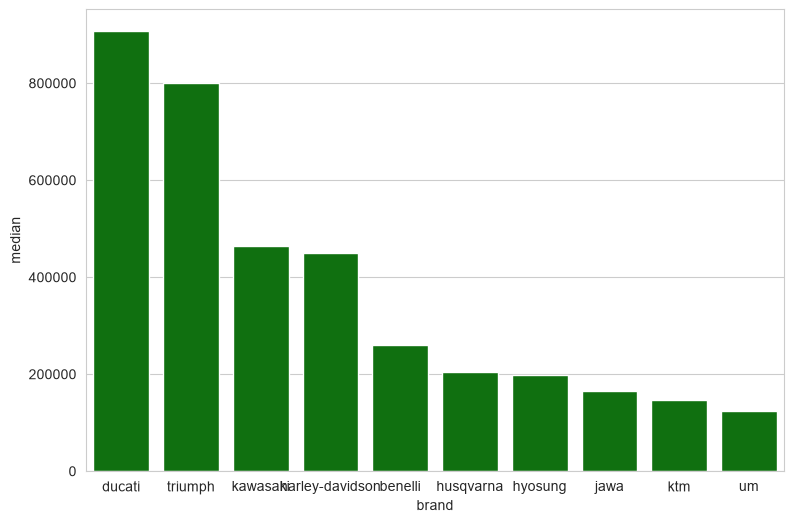

In [72]:
plt.figure(figsize=(9,6))
sns.barplot(data=brand_top_10, x='brand',y='median',color='green')

In [73]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,19.00,115000.00,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,34.00,100000.00,2025,bajaj
4,Jawa Perak 330cc 2020,True,2000.00,first owner,bangalore,NaN,30.00,197500.00,2025,jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,2025,yamaha
7853,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,7.00,28000.00,2025,bajaj
7854,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,2025,bajaj
7855,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,11.00,49000.00,2025,bajaj


In [74]:

df_clean=df_clean.dropna(subset=['mileage','power'])

In [75]:
df_clean.isna().sum()

model_name    0
model_year    0
kms_driven    3
owner         0
location      0
mileage       0
power         0
price         0
bike_age      0
brand         0
dtype: int64

<Axes: xlabel='kms_driven', ylabel='price'>

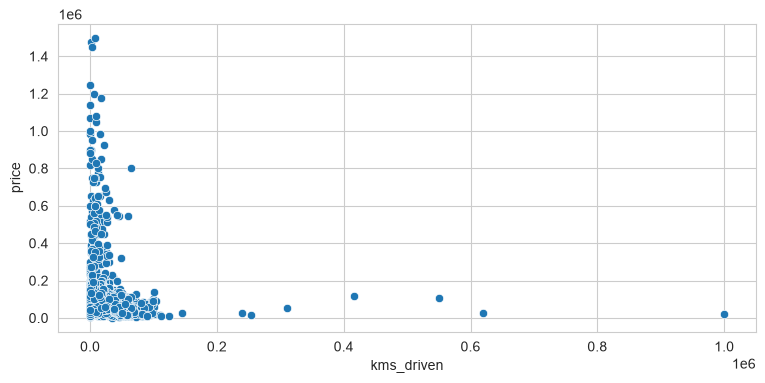

In [76]:
plot_data=df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
      plot_data=plot_data.sample(3000, random_state=42)


plt.figure(figsize=(9,4))

sns.scatterplot(data= plot_data,x='kms_driven',y='price',)

<Axes: xlabel='bike_age', ylabel='price'>

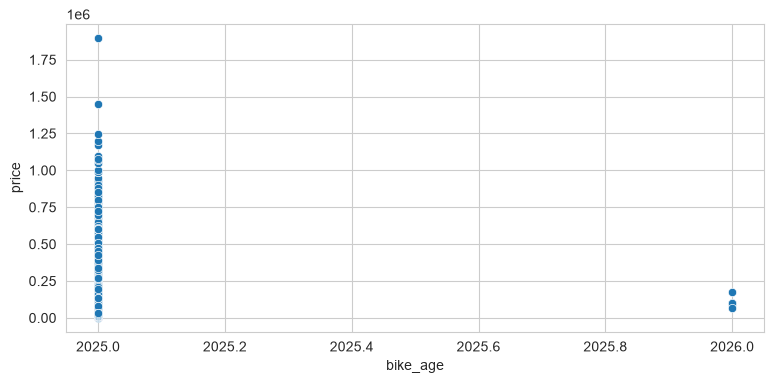

In [77]:
plot_data=df_clean.dropna(subset=['bike_age','price'])
if len(plot_data)>3000:
      plot_data=plot_data.sample(3000, random_state=42)


plt.figure(figsize=(9,4))
sns.scatterplot(data= plot_data,x='bike_age',y='price')

<Axes: >

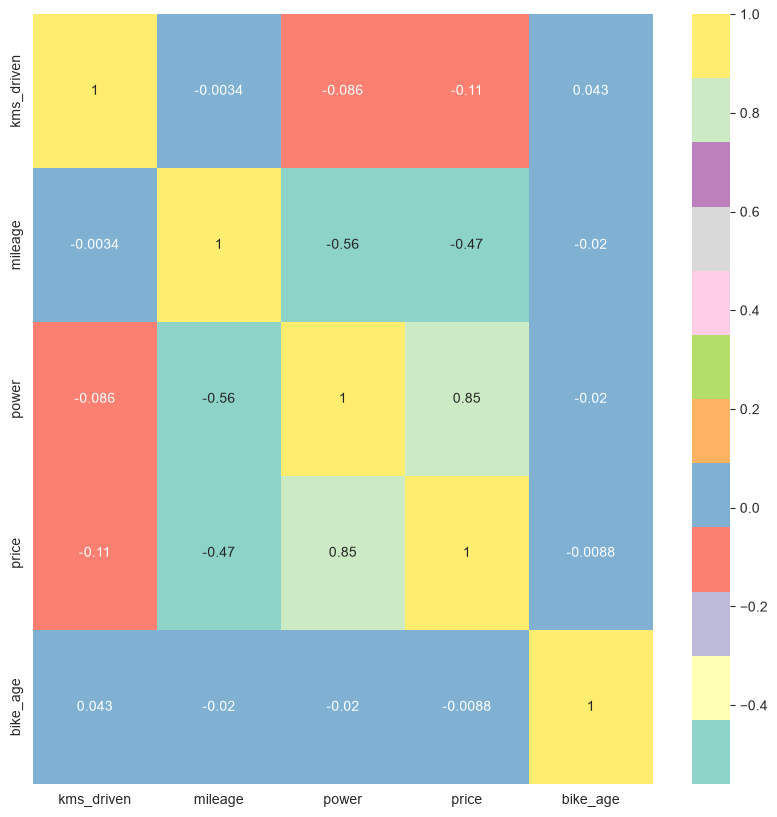

In [78]:
numeric_df= df_clean.select_dtypes(include='number')

plt.figure(figsize=(10,10))
sns.heatmap(numeric_df.corr(),annot=True,cmap='Set3')

In [79]:
df_clean.dropna(inplace=True)

In [80]:
df_clean.reset_index(inplace=True,drop='first')

In [81]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.00,first owner,hyderabad,35.00,19.00,63500.00,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.00,first owner,hyderabad,35.00,19.00,115000.00,2025,royal
2,Hyosung GT250R 2012,True,14795.00,first owner,hyderabad,30.00,28.00,300000.00,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.00,first owner,pondicherry,28.00,34.00,100000.00,2025,bajaj
4,KTM Duke 200cc 2012,True,24561.00,third owner,bangalore,35.00,25.00,63400.00,2025,ktm
...,...,...,...,...,...,...,...,...,...,...
7042,Yamaha YZF-R15 150cc 2011,True,7000.00,first owner,agra,42.00,16.00,55000.00,2025,yamaha
7043,Bajaj Discover 100cc 2015,True,80.00,first owner,delhi,80.00,7.00,28000.00,2025,bajaj
7044,Bajaj Pulsar 180cc 2016,True,6407.00,first owner,bangalore,65.00,17.00,61740.00,2025,bajaj
7045,Bajaj V15 150cc 2016,True,7524.00,first owner,bangalore,57.00,11.00,49000.00,2025,bajaj


In [82]:
data=df_clean.drop(['model_name','location','model_year'],axis=1)

In [83]:
data.columns

Index(['kms_driven', 'owner', 'mileage', 'power', 'price', 'bike_age',
       'brand'],
      dtype='str')

In [85]:
x=data[[ 'kms_driven', 'owner', 'mileage', 'power', 'price',
       'bike_age', 'brand']]
y=data['price']

In [86]:
from sklearn.model_selection import train_test_split
x_train,x_test, y_train,y_test=train_test_split(x,y, random_state=42,test_size=0.2)

In [87]:
numeric_columns = x.select_dtypes(include='number').columns.tolist()
categorical_columns = x.select_dtypes(exclude='number').columns.tolist()

In [88]:
numeric_pipeline= Pipeline(steps=[('imputer',SimpleImputer(strategy='median'))])
categorical_pipeline= Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),('ohe', OneHotEncoder(handle_unknown='ignore'))])

In [89]:
transformer=[]
if numeric_columns:
    transformer.append(("numeric",numeric_pipeline, numeric_columns))
if categorical_columns:
    transformer.append(("categorical",categorical_pipeline, categorical_columns))


preprocessor = ColumnTransformer(transformers=transformer)

model = Pipeline (steps =[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])


model.fit(x_train,y_train)
print("Linear Regression model trained")

Linear Regression model trained


In [96]:
y_pred = model.predict(x_test)

comparison = pd.DataFrame({
     "actual_price" : y_test.values,
     "prepredict_price" : np.round(y_pred, 0),
     "error_actual_minus_predicted" : np.round(y_test - y_pred, 0)
})
comparison["absolute_error"] = comparison["error_actual_minus_predicted"].abs()

display(comparison.head(15))

,actual_price,prepredict_price,error_actual_minus_predicted,absolute_error
3268,650000.00,650000.00,0.00,0.00
6576,111100.00,111100.00,-0.00,0.00
2181,125000.00,125000.00,-0.00,0.00
3245,42000.00,42000.00,0.00,0.00
3910,22540.00,22540.00,0.00,0.00
5657,127000.00,127000.00,-0.00,0.00
468,120000.00,120000.00,-0.00,0.00
6946,17500.00,17500.00,0.00,0.00
544,45000.00,45000.00,0.00,0.00
1488,92700.00,92700.00,-0.00,0.00


In [101]:
y_pred_train= model.predict(x_train)

mae = mean_absolute_error(y_train, y_pred_train)
mse = mean_squared_error(y_train, y_pred_train)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_pred_train)

print("MAE:  ₹{:,.0f}".format(mae))
print("MSE:  ₹{:,.0f}".format(mse))
print("RMSE:  ₹{:,.0f}".format(rmse))
print("R2:  ₹{:,.3f}".format(r2))

MAE:  ₹0
MSE:  ₹0
RMSE:  ₹0
R2:  ₹1.000


In [97]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:  ₹{:,.0f}".format(mae))
print("MSE:  ₹{:,.0f}".format(mse))
print("RMSE:  ₹{:,.0f}".format(rmse))
print("R2:  ₹{:,.3f}".format(r2))

MAE:  ₹0
MSE:  ₹0
RMSE:  ₹0
R2:  ₹1.000


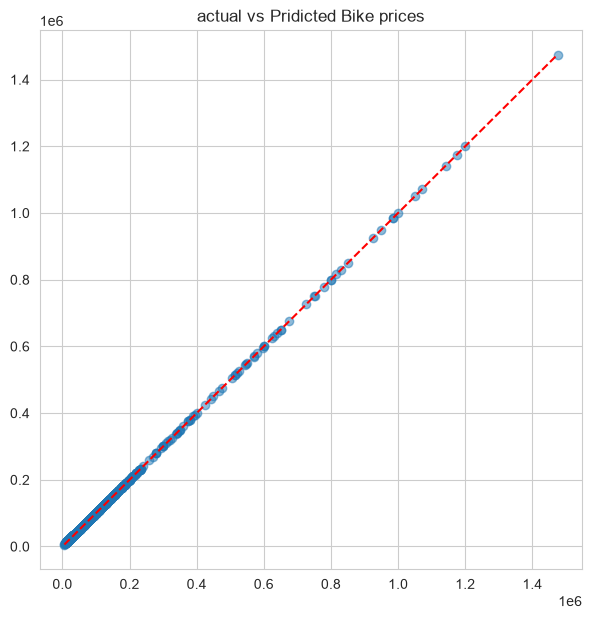

In [98]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.5)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")


plt.title("actual vs Pridicted Bike prices")
plt.show()

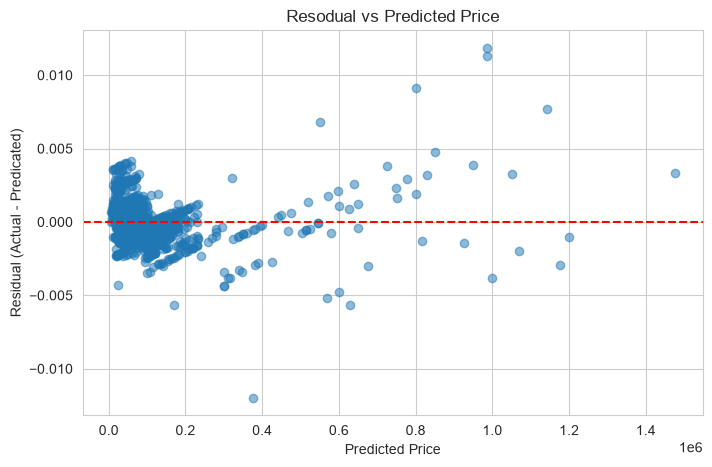

Mean residual: 0.0


In [99]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha = 0.5)
plt.axhline(0, color= "red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicated)")
plt.title("Resodual vs Predicted Price")
plt.show()
 

print("Mean residual:", round(residuals.mean(), 2))

In [100]:
import joblib
joblib.dump(model, "bike_price_linear_regression.joblib")

print("Saved bike_price_prediction.csv")
print("Saved bike_price_linear_regression.joblib")

Saved bike_price_prediction.csv
Saved bike_price_linear_regression.joblib
